# 3.4 Analysis and validation of the late-fusion gain

**Figure 5** (validation→test reliability; source of the gain), **Table 5** (per-member LOO/Shapley roles), **Figure S5** (member-role contributions), **Table S4** (inter-model correlation), **Figure S4** (correlation heatmaps). Recomputed from `../data/recompute_data/` via the shared setup cell.

In [1]:
# === Setup: figure/table regeneration for the ADMET multi-representation fusion paper ===
# Self-contained RECOMPUTATION from source predictions.
# Every figure/table quantity is recomputed here from raw per-seed per-molecule predictions
# (recompute_data/predictions/{model}.parquet), the per-model TDC leaderboard rankings
# (recompute_data/leaderboards/{model}.csv, direct training outputs), the 1023-subset uniform
# fusion sweep (recompute_data/all1023.csv), and the leaderboard
# ruler (recompute_data/tdc_leaderboard_snapshot.json). Nothing below is a hard-coded result;
# task metadata (ADMET group, training-set size, mechanism rationale) is loaded from
# recompute_data/task_metadata.json (fixed design labels, not recomputed). assert blocks verify the recomputed numbers against the
# manuscript values.
import os, json, io, itertools
from math import factorial
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr, kendalltau, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error
from statsmodels.stats.multitest import multipletests

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
RELDATA = os.path.join(HERE, "..", "data")          # release data/ dir (single canonical copy)
DATA = os.path.join(RELDATA, "recompute_data")
OUTDIR = os.path.join(HERE, "..", "figures"); os.makedirs(OUTDIR, exist_ok=True)  # write figures into release figures/ dir
META_GREY = "#888888"

def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")
    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif", "font.size": base, "axes.labelsize": base,
        "axes.titlesize": base, "legend.fontsize": secondary, "xtick.labelsize": tick,
        "ytick.labelsize": tick, "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid), "legend.frameon": False,
        "figure.dpi": 200, "savefig.dpi": 300, "savefig.bbox": "tight",
        "axes.titleweight": "normal", "axes.titlelocation": "left",
        "axes.labelweight": "normal", "lines.linewidth": 1.2, "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

REG  = json.load(open(f"{DATA}/task_registry.json"))
SNAP = json.load(open(f"{DATA}/tdc_leaderboard_snapshot.json"))
MODELS = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
TASKS  = [t for t in REG if t != "Bioavailability_Ma"]  # 21 evaluation tasks

def metric(name, y, p):
    """Compute a single TDC metric (mae/auroc/auprc/spearman) after dropping NaN labels."""
    y = np.asarray(y, float); p = np.asarray(p, float); m = ~np.isnan(y); y, p = y[m], p[m]
    if name == "mae":      return float(mean_absolute_error(y, p))
    if name == "auroc":    return float(roc_auc_score(y, p))
    if name == "auprc":    return float(average_precision_score(y, p))
    if name == "spearman": return float(spearmanr(y, p)[0])
    raise KeyError(name)

def norm_pct(score, task):
    """norm_score = fraction of TDC leaderboard models we beat (metric-direction aware)."""
    e = SNAP.get(task)
    if e is None or np.isnan(score): return np.nan
    s = [m["score"] for m in e["models"].values()]; met = REG[task]["metric"]
    worse = (sum(1 for x in s if x > score) if met == "mae" else sum(1 for x in s if x < score))
    return worse / len(s)

def rank_of(score, task):
    """Leaderboard rank of `score` for `task` (1 = best), metric-direction aware."""
    e = SNAP.get(task); met = REG[task]["metric"]
    s = [m["score"] for m in e["models"].values()]
    return (sum(1 for x in s if x < score) if met == "mae" else sum(1 for x in s if x > score)) + 1

# ---- load predictions (add replicate counter for exact merge keys) ----
PRED = {}
for m in MODELS:
    d = pd.read_parquet(f"{DATA}/predictions/{m}.parquet")
    PRED[m] = d.assign(rep=d.groupby(["seed","task","split","smiles"]).cumcount())

def merge_uniform(models, within):
    """Inner-join the given models' per-molecule predictions; add `yhat` = their uniform mean.
    within=True keeps the seed axis (matched-seed track); within=False averages predictions
    across seeds first (seed-averaged track). Returns the merged long DataFrame."""
    keys = ["seed","task","split","smiles","rep"] if within else ["task","split","smiles","rep"]
    if within:
        base = PRED[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(PRED[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    else:
        sm = {m: PRED[m].groupby(["task","split","smiles","rep"])
                       .agg(y_true=("y_true","first"), y_pred=("y_pred","mean")).reset_index() for m in models}
        base = sm[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(sm[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    base["yhat"] = base[[f"p_{m}" for m in models]].mean(axis=1)
    return base

def pertask_norm(models, within):
    """{task: norm_score} for the uniform-mean fusion of `models`, on the held-out test set.
    within=True: average the per-seed raw metric, then normalize once; within=False: score once on
    the seed-averaged predictions."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            seed_sc = [metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]
            res[task] = norm_pct(float(np.mean(seed_sc)), task)
        else:
            res[task] = norm_pct(metric(met, t.y_true, t.yhat), task)
    return res

def pertask_raw(models, within):
    """{task: raw_score} for the uniform-mean fusion of `models`, held-out test set.
    Mirror of pertask_norm but returns the raw metric value (before leaderboard normalization).
    within=True: mean over the per-seed metric (matched-seed track)."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            res[task] = float(np.mean([metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]))
        else:
            res[task] = float(metric(met, t.y_true, t.yhat))
    return res

def subset_norm(models, within):
    """Mean of pertask_norm across the 21 evaluation tasks (one scalar per subset)."""
    return float(np.mean(list(pertask_norm(models, within).values())))

# ---- correlation matrices (exact XAI method) ----
def corr_matrices(within):
    """Mean off-diagonal |correlation| among the k=5 ensemble members, for both the
    standardized predictions and the standardized residuals (prediction - truth).

    Returns (pred_corr, resid_corr): how redundant the members' outputs / errors are.
    within=True  -> matched-seed track: correlate per (task, seed), average the matrices.
    within=False -> seed-averaged track: pool all test rows per task, correlate once.
    (This is the exact 'XAI' correlation recipe used in the analysis notebooks.)
    """
    pred_cols = [f"p_{m}" for m in ENSEMBLE]
    base = merge_uniform(ENSEMBLE, within)
    if not within:
        # seed-averaged: concatenate standardized vectors across all tasks, one corr matrix
        pred_z  = {m: [] for m in ENSEMBLE}   # standardized predictions per member
        resid_z = {m: [] for m in ENSEMBLE}   # standardized residuals per member
        for task in TASKS:
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            for j, m in enumerate(ENSEMBLE):
                p = preds[:, j]; pred_z[m].append((p - p.mean())/(p.std()+1e-9))
                resid = p - y_true; resid_z[m].append((resid - resid.mean())/(resid.std()+1e-9))
        pred_z  = {m: np.concatenate(v) for m, v in pred_z.items()}
        resid_z = {m: np.concatenate(v) for m, v in resid_z.items()}
        pred_corr_mat  = np.corrcoef([pred_z[m]  for m in ENSEMBLE])
        resid_corr_mat = np.corrcoef([resid_z[m] for m in ENSEMBLE])
    else:
        # matched-seed: one corr matrix per (task, seed), then average across all of them
        seeds = sorted(base.seed.unique()); pred_mats = []; resid_mats = []
        for task in TASKS:
            task_rows = base[base.task==task]
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows) < 3: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                pred_z_seed = []; resid_z_seed = []
                for j, m in enumerate(ENSEMBLE):
                    p = preds[:, j]
                    pred_z_seed.append((p - p.mean())/(p.std()+1e-9))
                    resid_z_seed.append((p - y_true) - (p - y_true).mean()/((p - y_true).std()+1e-9))
                pred_mats.append(np.corrcoef(pred_z_seed)); resid_mats.append(np.corrcoef(resid_z_seed))
        pred_corr_mat  = np.nanmean(pred_mats, 0)
        resid_corr_mat = np.nanmean(resid_mats, 0)
    upper = np.triu_indices(len(ENSEMBLE), 1)   # off-diagonal (unordered pairs)
    return float(np.abs(pred_corr_mat[upper]).mean()), float(np.abs(resid_corr_mat[upper]).mean())

# ---- winners + best-single mean rank ----
def winners_best(within):
    """Per-task winner counts among the k=5 members + the best single member's mean TDC rank.

    Returns (wins, best_model, best_mean_rank):
      wins           - {model: number of tasks where it is the single best member}
      best_model     - member with the lowest mean leaderboard rank across tasks
      best_mean_rank - that member's mean rank (the single-model baseline the ensemble beats)
    within=True  -> matched-seed: winner decided per (task, seed); rank from seed-mean score.
    within=False -> seed-averaged: winner decided once per task on the seed-averaged score.
    """
    from collections import Counter
    base = merge_uniform(ENSEMBLE, within); pred_cols = [f"p_{m}" for m in ENSEMBLE]
    if not within:
        wins = Counter(); member_ranks = {m: [] for m in ENSEMBLE}   # per-task leaderboard rank
        for task in TASKS:
            met = REG[task]["metric"]
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
            wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
            for m in ENSEMBLE: member_ranks[m].append(rank_of(member_score[m], task))
    else:
        seeds = sorted(base.seed.unique()); wins = Counter(); member_score_by_task = {m: [] for m in ENSEMBLE}
        for task in TASKS:
            met = REG[task]["metric"]; task_rows = base[base.task==task]; seed_scores = {m: [] for m in ENSEMBLE}
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows)==0: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
                wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
                for m in ENSEMBLE: seed_scores[m].append(member_score[m])
            for m in ENSEMBLE: member_score_by_task[m].append(np.mean(seed_scores[m]))
        member_ranks = {m: [rank_of(member_score_by_task[m][i], TASKS[i]) for i in range(len(TASKS))] for m in ENSEMBLE}
    best_model = min(ENSEMBLE, key=lambda m: np.mean(member_ranks[m]))
    return dict(wins), best_model, float(np.mean(member_ranks[best_model]))

# ---- ensemble mean TDC rank (Score-then-Rank), within + cross ----
def ensemble_mean_rank():
    """Mean TDC leaderboard rank of the k=5 ensemble across tasks (Score-then-Rank).
    Returns (mean_rank_within, mean_rank_cross)."""
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False)
    ranks_w = []; ranks_c = []
    for task in TASKS:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ranks_w.append(rank_of(float(np.mean(seed_sc)), task))
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        ranks_c.append(rank_of(metric(met, tc.y_true, tc.yhat), task))
    return float(np.mean(ranks_w)), float(np.mean(ranks_c))

# ---- LOO + Shapley (over all 31 non-empty subsets of ENSEMBLE) ----
def loo_shapley():
    """Leave-one-out and Shapley contribution of each k=5 member to the ensemble norm_score.

    Enumerates all 31 non-empty subsets of ENSEMBLE and scores each (within + cross track):
      loo_within/cross    = value(full) - value(full minus this member)  (removal effect)
      shapley_within/cross= mean marginal contribution over all coalitions (Shapley value)
    Returns (per_member_dict, value_full_within, value_full_cross).
    """
    value_within = {}; value_cross = {}
    for size in range(1, len(ENSEMBLE)+1):
        for combo in itertools.combinations(ENSEMBLE, size):
            key = tuple(sorted(combo))
            value_within[key] = subset_norm(list(combo), True)
            value_cross[key]  = subset_norm(list(combo), False)
    full = tuple(sorted(ENSEMBLE)); n_members = len(ENSEMBLE)
    def shapley(value):
        contrib = {m: 0.0 for m in ENSEMBLE}
        for m in ENSEMBLE:
            others = [x for x in ENSEMBLE if x != m]
            for size in range(len(others)+1):
                for coalition in itertools.combinations(others, size):
                    weight = factorial(len(coalition))*factorial(n_members-len(coalition)-1)/factorial(n_members)
                    with_m    = value[tuple(sorted(coalition+(m,)))]
                    without_m = value[tuple(sorted(coalition))] if coalition else 0.0
                    contrib[m] += weight*(with_m - without_m)
        return contrib
    shap_within = shapley(value_within); shap_cross = shapley(value_cross); out = {}
    for m in ENSEMBLE:
        out[m] = {
            "within_solo": value_within[(m,)],
            "loo_within":  value_within[full] - value_within[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "cross_solo":  value_cross[(m,)],
            "loo_cross":   value_cross[full]  - value_cross[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "shapley_within": shap_within[m], "shapley_cross": shap_cross[m]}
    return out, value_within[full], value_cross[full]

# ---- MAP vs mean/max aggregation (leaderboard.csv `ours` -> re-ranked) ----
def map_agg():
    """MAP (joint latent fusion) vs naive mean/best aggregation of the 3 shared backbones,
    per training regime (mtl/stl). Uses leaderboard.csv `ours` scores re-normalized against
    the TDC snapshot. Returns (summary_dict, long_leaderboard_df)."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    def to_norm(ds, score):
        e = SNAP.get(ds)
        if e is None or pd.isna(score): return np.nan
        met = REG[ds]["metric"]; s = [x["score"] for x in e["models"].values()]
        rank = (sum(1 for x in s if x < score) if met=="mae" else sum(1 for x in s if x > score))+1
        return (len(s)-rank+1)/len(s)
    BACKS = ["chemeleon","graphmvp","molformer"]; res = {}
    for train in ["mtl","stl"]:
        bm = [f"{train}_{b}" for b in BACKS]
        piv = LONG[LONG.model.isin(bm)].pivot_table(index=["dataset","metric"], columns="model", values="ours", aggfunc="first")
        mp = LONG[LONG.model==f"{train}_map"].set_index("dataset").apply(lambda r: to_norm(r.name, r["ours"]), axis=1)
        mn = {}; mx = {}
        for (ds,met),row in piv.iterrows():
            vals = row[bm].dropna()
            if vals.empty: continue
            direction = SNAP.get(ds,{}).get("direction","higher")
            mn[ds] = to_norm(ds, vals.mean()); mx[ds] = to_norm(ds, vals.max() if direction=="higher" else vals.min())
        common = [d for d in mp.index if d in mn]
        mpv = mp[common]; mnv = pd.Series(mn)[common]; mxv = pd.Series(mx)[common]
        res[train] = {"map":round(float(mpv.mean()),3),"mean":round(float(mnv.mean()),3),"best":round(float(mxv.mean()),3),
                      "map_gt_mean":f"{int((mpv>mnv).sum())}/{len(common)}",
                      "map_gt_best":f"{int((mpv>mxv).sum())}/{len(common)}","n":len(common)}
    return res, LONG

# ---- ensemble-size sweep (top-20 mean per k over 1023 uniform subsets) ----
def ksweep():
    # all1023.csv: the uniform-mean fusion sweep over all 1,023 non-empty subsets of the 10
    #   base models, scored on both validation and the held-out TDC test split (matched-seed
    #   'within' and seed-averaged 'cross' tracks). One row per subset; columns:
    #   combo_key (comma-joined member list), k, {val,test}_{within,cross}, {val,test}_comb.
    #   The ensemble-size selection uses the VALIDATION columns only (val_within/val_cross);
    #   the test columns are the same file's source for the Figure 5 reliability scatter.
    #   Feeds Figure 3 + Table S3 (validation top-20-mean norm_score per k -> elbow at k=5).
    #   This file is fully regenerable from the 10 predictions/*.parquet via code/make_all1023.py
    #   (predictions -> script -> csv closure); nothing here is hard-coded.
    s1 = pd.read_csv(f"{DATA}/all1023.csv")
    s1["k"] = s1.combo_key.apply(lambda b: len(b.split(",")))
    def topN(col, N=20):
        return {k: round(s1[s1.k==k].nlargest(min(N,(s1.k==k).sum()), col)[col].mean(),4) for k in range(1,11)}
    tw = topN("val_within"); tc = topN("val_cross")
    rows = []
    for k in range(1,11):
        rows.append([k, tw[k], round(tw[k]-tw[k-1],4) if k>1 else None,
                        tc[k], round(tc[k]-tc[k-1],4) if k>1 else None])
    return rows

# ---- validation->test rank reliability (all 1023 subsets) ----
def val_test_corr():
    # all1023.csv: uniform-mean fusion scored on BOTH validation and the fixed TDC test set,
    #   for every one of the 1,023 non-empty subsets. One row per subset; columns:
    #   combo_key (member list), k, val_within, val_cross, test_within, test_cross,
    #   val_comb, test_comb. This is the source for Figure 4a's validation->test rank
    #   reliability scatter, which uses the val_* -> test_* columns of the same sweep file.
    #   Same source as ksweep() (Figure 3); regenerable via code/make_all1023.py.
    from scipy.stats import spearmanr as _sp, kendalltau as _kt
    a = pd.read_csv(f"{DATA}/all1023.csv"); out = {}
    for name,vc,tc in [("within","val_within","test_within"),("cross","val_cross","test_cross"),("combined","val_comb","test_comb")]:
        out[name] = {"rho": round(_sp(a[vc],a[tc])[0],4), "tau": round(_kt(a[vc],a[tc])[0],4)}
    out["n_configs"] = len(a); return out

# ---- statistical tests (ensemble vs deployable singles + per-task oracle) ----
def stat_tests():
    ens_w = pertask_norm(ENSEMBLE, True); ens_c = pertask_norm(ENSEMBLE, False)
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    LONG["norm"] = (LONG.n_total - LONG["rank"] + 1)/LONG.n_total
    lbp = LONG.pivot_table(index="dataset", columns="model", values="norm").loc[TASKS]
    baselines = {"CheMeleon\u00b7STL":"stl_chemeleon","MAP\u00b7STL":"stl_map","D-MPNN\u00b7MTL":"mtl_dmpnn"}
    dep = {}; ora = {}
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        e = np.array([ens[t] for t in TASKS])
        for disp, m in baselines.items():
            b = lbp[m].to_numpy(); de = e - b; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
            dep[f"{disp}|{track}"] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
                "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(b.mean())}
        oc = lbp.max(axis=1).to_numpy(); de = e - oc; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
        ora[track] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
            "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(oc.mean())}
    return {"deployable_single":dep, "per_task_oracle":ora, "n_tasks":len(TASKS),
            "ensemble_mean":{"within":float(np.mean(list(ens_w.values()))),"cross":float(np.mean(list(ens_c.values())))}}

# ---- per-task tables t1 (per-backbone), t3 (MAP/mean/max), t4 (ensemble) ----
def leaderboard_long():
    """Concatenate every model's leaderboard.csv into one long frame with a `norm` column."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    L = pd.concat(lbs, ignore_index=True)
    L["norm"] = (L.n_total - L["rank"] + 1)/L.n_total
    return L

def table_t1(meta):
    """per-backbone per-task raw+norm on the WITHIN-SEED (matched-seed) basis: each seed is
    scored separately, the five raw scores are averaged, and that mean is normalized once (identical
    basis to Figure 1a / Table 3). meta = {task:{group,n}}. norm rounded to 3 decimals."""
    BB = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
    raw = {b: pertask_raw([b], True)  for b in BB}
    nrm = {b: pertask_norm([b], True) for b in BB}
    rows = []
    for task, mrec in meta.items():
        e = {"group": mrec["group"], "dataset": task, "n": mrec["n"], "metric": REG[task]["metric"]}
        for b in BB:
            e[b] = {"raw": round(float(raw[b][task]),3), "norm": round(float(nrm[b][task]),3)}
        rows.append(e)
    return rows

def table_t3(meta3):
    """MAP / latent-mean / latent-best per-task raw+norm on the WITHIN-SEED basis. MAP is the
    joint-fusion model's own per-seed prediction; latent mean/best aggregate the three backbones'
    per-seed scores (mean or direction-aware best) per seed, then norm and average. meta3 = {task:{group}}."""
    BACKS = ["chemeleon","graphmvp","molformer"]
    def agg_within(train, task, how):
        # Reference lines for the three MAP backbones, on the SAME basis as every other
        # normalized value in this release (Method A): aggregate in RAW score space first,
        # normalize exactly once at the end.
        #   step 1  per encoder, average the raw metric over the five seeds (= its Table S1 value)
        #   step 2  across the three encoders take the mean, or the best in the metric direction
        #   step 3  map that single raw value through norm_pct once
        # Aggregating inside each seed and normalizing per seed instead would make `best` a
        # per-seed oracle whose raw value matches no individual backbone, and would break
        # monotonicity between the raw and normalized columns because norm_pct is a step
        # function of the raw metric.
        met = REG[task]["metric"]
        enc_raw = {}
        for bb in BACKS:
            d = PRED[f"{train}_{bb}"]
            per_seed = []
            for seed in sorted(d.seed.unique()):
                t = d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
                per_seed.append(metric(met, t.y_true, t.y_pred))
            enc_raw[bb] = float(np.mean(per_seed))
        vals = list(enc_raw.values())
        raw = float(np.mean(vals)) if how=="mean" else float(min(vals) if met=="mae" else max(vals))
        return raw, float(norm_pct(raw, task))
    map_raw = {tr: pertask_raw([f"{tr}_map"], True)  for tr in ["mtl","stl"]}
    map_nrm = {tr: pertask_norm([f"{tr}_map"], True) for tr in ["mtl","stl"]}
    rows = []
    for task, mrec in meta3.items():
        met = REG[task]["metric"]; e = {"group": mrec["group"], "dataset": task, "metric": met}
        for train in ["mtl","stl"]:
            e[f"{train}_map"]  = {"raw": round(float(map_raw[train][task]),3), "norm": round(float(map_nrm[train][task]),3)}
            mr, mn = agg_within(train, task, "mean"); br, bn = agg_within(train, task, "best")
            e[f"{train}_mean"] = {"raw": round(mr,3), "norm": round(mn,3)}
            e[f"{train}_best"] = {"raw": round(br,3), "norm": round(bn,3)}
        rows.append(e)
    return rows

def table_t4():
    """ensemble per-task within/cross score+norm+rank over ALL 22 tasks (incl Bioavailability_Ma)."""
    allt = list(REG)
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False); rows = []
    for task in allt:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ws = float(np.mean(seed_sc)); ws_std = float(np.std(seed_sc, ddof=0))  # ddof=0 matches TDC ours_std
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        cs = metric(met, tc.y_true, tc.yhat)
        def _n(x, nd=3):  # int for exact 0/1 (match hardcoded schema), else float rounded to nd
            return int(x) if float(x).is_integer() else round(float(x), nd)
        rows.append({"task":task, "metric":met,
                     "within_score":round(ws,6), "within_std":round(ws_std,6), "within_norm":_n(norm_pct(ws,task),3), "within_rank":rank_of(ws,task),
                     "cross_score":round(cs,6),  "cross_norm":_n(norm_pct(cs,task),3),  "cross_rank":rank_of(cs,task)})
    return rows

# ---- Figure-1 within-seed solo + per-task (predictions basis) ----
def fig1_data(groups):
    """Figure 1 inputs on the within-seed (matched-seed) basis: per-model solo norm_score
    (`solo`), per-model per-task norm (`pertask`), and the ADMET mechanism `groups`."""
    solo = {m: subset_norm([m], True) for m in MODELS}
    pertask = []
    for task in TASKS:
        rec = {"task": task}
        for m in MODELS:
            rec[m] = pertask_norm([m], True)[task]
        pertask.append(rec)
    return {"solo": solo, "pertask": pertask, "groups": groups}

# ---- assemble full _GT / _PT / _FIG1 / _ST ----
def build_all(meta1, meta3, groups, t2, const_gt):
    lo, ens_w, ens_c = loo_shapley()
    cw = corr_matrices(True); cc = corr_matrices(False)
    win_w, bs_w, bsr_w = winners_best(True); win_c, bs_c, bsr_c = winners_best(False)
    mag, _ = map_agg()
    GT = dict(const_gt)  # final_ensemble, headline, sota_tasks, etc (constants)
    GT["map_agg"] = {t: {k: mag[t][k] for k in ["map","mean","best","map_gt_mean","map_gt_best"]} for t in ["mtl","stl"]}
    GT["ksweep"] = ksweep()
    GT["corr"] = {"within": {"pred_offdiag": round(cw[0],3), "resid_offdiag": round(cw[1],3)},
                  "cross":  {"pred_offdiag": round(cc[0],3), "resid_offdiag": round(cc[1],3)}}
    # ens_rank = mean TDC rank of the k=5 uniform ensemble across the 21 tasks (Score-then-Rank),
    # recomputed here (NOT a literal): within uses per-seed→mean→rank, cross uses seed-meaned→rank.
    ens_rank_w, ens_rank_c = ensemble_mean_rank()
    GT["best_single"] = {"within": {"model": bs_w, "mean_rank": round(bsr_w,3), "ens_rank": round(ens_rank_w,3)},
                         "cross":  {"model": bs_c, "mean_rank": round(bsr_c,3), "ens_rank": round(ens_rank_c,3)}}
    # per member -> [0]=within_solo  [1]=loo_within  [2]=cross_solo
    #                [3]=loo_cross    [4]=shapley_within  [5]=shapley_cross
    GT["loo_shapley"] = {b: [round(lo[b]["within_solo"],4), round(lo[b]["loo_within"],4),
                             round(lo[b]["cross_solo"],4), round(lo[b]["loo_cross"],4),
                             round(lo[b]["shapley_within"],4), round(lo[b]["shapley_cross"],4)] for b in ENSEMBLE}
    GT["winners"] = {"cross": {m: win_c.get(m,0) for m in ENSEMBLE},
                     "within_taskseed": {m: win_w.get(m,0) for m in ENSEMBLE}}
    GT["full_ensemble_norm"] = {"within": round(ens_w,4), "cross": round(ens_c,4)}
    PT = {"t1": table_t1(meta1), "t3": table_t3(meta3), "t4": table_t4(), "t2": t2}
    FIG1 = fig1_data(groups)
    ST = stat_tests()
    return GT, PT, FIG1, ST


# --- task metadata (fixed design labels, not recomputed): loaded from recompute_data/task_metadata.json ---
_TASK_META = json.load(open(f"{DATA}/task_metadata.json"))
_META1   = _TASK_META["meta1"]                                   # {task: {group, n}}
_META3   = {t: {"group": v["group"]} for t, v in _META1.items()} # meta1 without training-set size
_GROUPS  = _TASK_META["groups"]                                  # {mechanism group: [tasks]}
_T2      = _TASK_META["t2"]                                      # [{group, tasks, rationale}]
_CONST_GT = _TASK_META["const_gt"]                               # final_ensemble / final_composition / ...
ENSEMBLE  = list(_CONST_GT["final_ensemble"])                    # final k=5 members (single source of truth)


# --- recompute everything from source ---
_GT, _PT, _FIG1, _ST = build_all(_META1, _META3, _GROUPS, _T2, _CONST_GT)

# --- solo per-task within/cross norm (recomputed from predictions+leaderboards; replaces solo_pertask_within_cross.csv / fig1_within_pertask.csv) ---
# Per-(model, task) solo within/cross norm_score, recomputed from source predictions +
# leaderboard rankings. Replaces the released solo_pertask_within_cross.csv and
# fig1_within_pertask.csv (values verified identical to 1e-16).
# Row order matters ONLY for Figure 4d's winner-per-task argmax under exact norm ties
# (several tasks tie to the 4th decimal); we emit rows in the exact model/task order of
# the original fig1_within_pertask.csv so idxmax tie-breaking reproduces the published
# Figure 4d winner distribution (8/5/4/3/1). The norm values themselves are order-independent.
_SOLO_MODEL_ORDER = ["mtl_dmpnn","stl_dmpnn","stl_map","stl_chemeleon","stl_graphmvp",
                     "stl_molformer","mtl_graphmvp","mtl_molformer","mtl_chemeleon","mtl_map"]
_SOLO_TASK_ORDER  = ["HIA_Hou","Pgp_Broccatelli","BBB_Martins","CYP2C9_Veith","CYP2D6_Veith",
                     "CYP3A4_Veith","CYP2C9_Substrate_CarbonMangels","CYP2D6_Substrate_CarbonMangels",
                     "CYP3A4_Substrate_CarbonMangels","hERG","AMES","DILI","Caco2_Wang",
                     "Lipophilicity_AstraZeneca","Solubility_AqSolDB","PPBR_AZ","VDss_Lombardo",
                     "Half_Life_Obach","Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ","LD50_Zhu"]
def _solo_pertask_frame():
    per_model_within = {m: pertask_norm([m], True)  for m in _SOLO_MODEL_ORDER}
    per_model_cross  = {m: pertask_norm([m], False) for m in _SOLO_MODEL_ORDER}
    rows = []
    for m in _SOLO_MODEL_ORDER:
        for t in _SOLO_TASK_ORDER:
            rows.append({"model": m, "task": t,
                         "group":  _META1.get(t, {}).get("group", ""),
                         "metric": REG[t]["metric"],
                         "within_norm": per_model_within[m][t],
                         "cross_norm":  per_model_cross[m][t]})
    return pd.DataFrame(rows)
_SOLO_PT = _solo_pertask_frame()   # 210 rows = 10 backbones x 21 evaluation tasks

# --- assert recomputed values reproduce the manuscript (tolerance = rounding) ---
assert abs(_FIG1["solo"]["stl_chemeleon"] - 0.6331) < 0.002, _FIG1["solo"]["stl_chemeleon"]
assert abs(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8539) < 0.002
assert abs(np.mean([e["cross_norm"]  for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8971) < 0.002
assert _GT["winners"]["cross"]["mtl_dmpnn"] == 6 and _GT["winners"]["within_taskseed"]["mtl_dmpnn"] == 36
assert abs(_GT["map_agg"]["mtl"]["map"] - 0.621) < 0.002 and abs(_GT["map_agg"]["stl"]["map"] - 0.609) < 0.002
assert abs(_GT["corr"]["cross"]["pred_offdiag"] - 0.878) < 0.002 and abs(_GT["corr"]["within"]["pred_offdiag"] - 0.767) < 0.002
assert abs(_GT["ksweep"][4][1] - 0.8252) < 0.002 and abs(_GT["ksweep"][3][1] - 0.8198) < 0.002
assert abs(_GT["best_single"]["cross"]["mean_rank"] - 5.476) < 0.01 and abs(_GT["best_single"]["within"]["mean_rank"] - 8.429) < 0.01
assert len(_PT["t1"]) == 21 and len(_PT["t3"]) == 21 and len(_PT["t4"]) == 22

print("setup ok | recomputed from source | tasks:", len(_PT["t1"]),
      "| final ensemble:", _GT["final_ensemble"],
      "| ens within/cross norm:", round(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4),
      round(np.mean([e["cross_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4))


# --- consolidated-workbook helpers (from tables notebook) ---
OUT = "../tables"; os.makedirs(OUT, exist_ok=True)
TABLES = {}
def register(name, df, index=False):
    TABLES[name] = (df, index)
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
    return df

BACKBONES = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
             "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
BB_LABEL  = {"mtl_dmpnn":"D-MPNN MTL","mtl_chemeleon":"CheMeleon MTL","mtl_graphmvp":"GraphMVP MTL",
             "mtl_molformer":"MoLFormer MTL","stl_dmpnn":"D-MPNN STL","stl_chemeleon":"CheMeleon STL",
             "stl_graphmvp":"GraphMVP STL","stl_molformer":"MoLFormer STL"}
def cell(d):  # "raw (norm_score)" — norm shown to 3 decimals (unified precision)
    return f'{d["raw"]:g} ({d["norm"]:.3f})'
print("recomputed pertask + ground_truth from source; backbones:", len(BACKBONES),
      "| S1 tasks:", len(_PT["t1"]), "| ksweep k:", len(_GT["ksweep"]))


setup ok | recomputed from source | tasks: 21 | final ensemble: ['mtl_dmpnn', 'mtl_molformer', 'stl_chemeleon', 'stl_graphmvp', 'stl_map'] | ens within/cross norm: 0.854 0.8971
recomputed pertask + ground_truth from source; backbones: 8 | S1 tasks: 21 | ksweep k: 10


# 3.4 Analysis and validation of the late-fusion gain

## Fig. 5 Source and robustness of the late-fusion gain.

saved figure5.png (2-panel: a scatter, b raw-score winners {'mtl_dmpnn': 7, 'mtl_molformer': 6, 'stl_chemeleon': 3, 'stl_graphmvp': 1, 'stl_map': 4} )


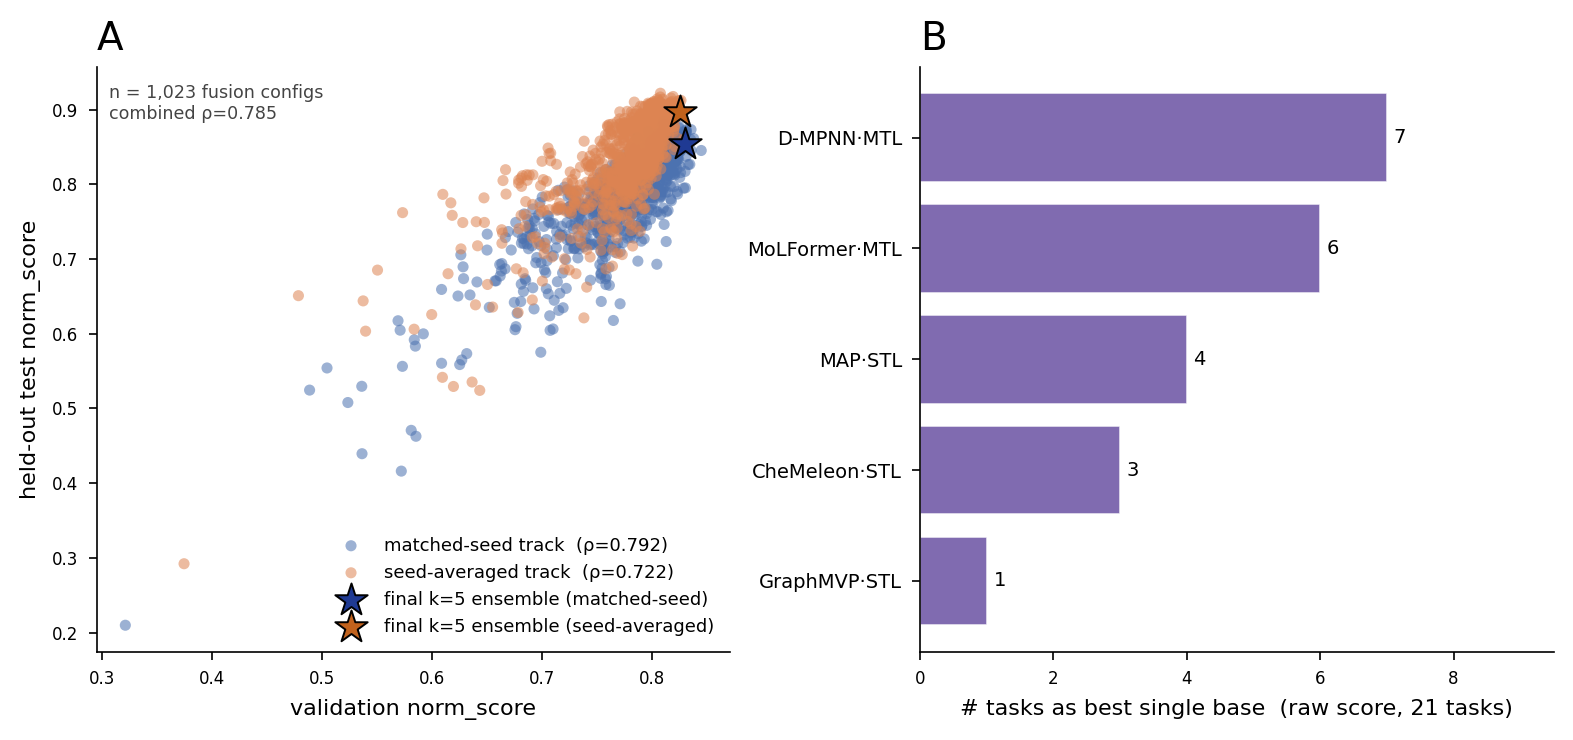

In [2]:
# === figure5.png (validation→test reliability + task-wise specialization) ===
import json, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr, kendalltau

apply_figure_style(sizes=(8,7,6))
GT = _GT; PT = _PT
PRETTY = {
 "stl_chemeleon":"CheMeleon·STL","mtl_chemeleon":"CheMeleon·MTL",
 "stl_map":"MAP·STL","mtl_map":"MAP·MTL",
 "stl_dmpnn":"D-MPNN·STL","mtl_dmpnn":"D-MPNN·MTL",
 "stl_graphmvp":"GraphMVP·STL","mtl_graphmvp":"GraphMVP·MTL",
 "stl_molformer":"MoLFormer·STL","mtl_molformer":"MoLFormer·MTL",
}
STLc="#4c72b0"; MTLc="#dd8452"

# Panel A uses ALL 1,023 non-empty subsets (matches Section 3.4 body text).
vt=pd.read_csv(f"{DATA}/all1023.csv")
rw,_=spearmanr(vt.val_within, vt.test_within)   # matched-seed track
rc,_=spearmanr(vt.val_cross, vt.test_cross)     # seed-averaged track
rcomb2,_=spearmanr(vt.val_comb, vt.test_comb)
FINAL_KEY=",".join(sorted(GT["final_ensemble"]))

plt.close('all')
fig=plt.figure(figsize=(9.4,3.8))
gs=fig.add_gridspec(1,2, wspace=0.30)

# Panel a: validation vs held-out-test norm_score, both tracks
axA=fig.add_subplot(gs[0,0])
axA.scatter(vt.val_within, vt.test_within, s=16, color=STLc, alpha=0.55, edgecolor="none", label=f"matched-seed track  (\u03c1={rw:.3f})")
axA.scatter(vt.val_cross, vt.test_cross, s=16, color=MTLc, alpha=0.55, edgecolor="none", label=f"seed-averaged track  (\u03c1={rc:.3f})")
fk=vt[vt.combo_key==FINAL_KEY].iloc[0]
# final k=5 ensemble star, coloured by track (dark tones + black edge to stand out from the clouds)
STAR_W="#1f3a93"; STAR_C="#c1621d"   # matched-seed (dark blue), seed-averaged (dark orange)
axA.scatter([fk.val_within],[fk.test_within], s=150, marker="*", color=STAR_W, edgecolor="black", lw=0.7, zorder=5, label="final k=5 ensemble (matched-seed)")
axA.scatter([fk.val_cross],[fk.test_cross], s=150, marker="*", color=STAR_C, edgecolor="black", lw=0.7, zorder=5, label="final k=5 ensemble (seed-averaged)")
axA.set_xlabel("validation norm_score"); axA.set_ylabel("held-out test norm_score")
axA.set_title("A", fontsize=14)
# axA.set_title("a  Validation reliably ranks test performance", loc="left", fontweight="bold", fontsize=9)
axA.legend(fontsize=6.5, frameon=False, loc="lower right")
axA.text(0.02,0.97, f"n = {len(vt):,} fusion configs\ncombined \u03c1={rcomb2:.3f}",
         transform=axA.transAxes, va="top", fontsize=6.3, color="#444")

# Panel b: task-wise winner distribution among the k=5 members, ranked by RAW score
# (direction-aware: mae -> lowest raw wins, else highest raw wins). raw_score avoids the
# norm_score tie-boundary ambiguity; each of the 21 tasks has exactly one winner (no ties).
axB=fig.add_subplot(gs[0,1])
_wm=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_graphmvp","stl_map"]
def _raw_within(model):
    base=merge_uniform([model], True); out={}
    for task in TASKS:
        met=REG[task]["metric"]
        t=base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        out[task]=float(np.mean([metric(met, gg.y_true, gg.yhat) for _,gg in t.groupby("seed")]))
    return out
_raw={m:_raw_within(m) for m in _wm}
win={m:0 for m in _wm}
for task in TASKS:
    met=REG[task]["metric"]; vals=[(_raw[m][task],m) for m in _wm]
    win[(min if met=="mae" else max)(vals)[1]] += 1
_WIN_RAW = dict(win)   # stashed (sum=21, no ties)
wmembers=["mtl_dmpnn","mtl_molformer","stl_map","stl_chemeleon","stl_graphmvp"]
wvals=[win[m] for m in wmembers]; wlab=[PRETTY[m] for m in wmembers]
yb=np.arange(len(wmembers))[::-1]
axB.barh(yb, wvals, color="#6a51a3", alpha=0.85, edgecolor="white")
axB.set_yticks(yb); axB.set_yticklabels(wlab, fontsize=7)
for y_,v in zip(yb,wvals): axB.text(v+0.1, y_, str(v), va="center", fontsize=7)
axB.set_xlabel("# tasks as best single base  (raw score, 21 tasks)")
axB.set_title("B", fontsize=14)
# axB.set_title("b  Gain comes from task-wise specialization", loc="left", fontweight="bold", fontsize=9)
axB.set_xlim(0,9.5)
corr=GT["corr"]["within"]
# axB.text(0.985,0.46,
#          f"Member predictions highly correlated\n(pred r={corr['pred_offdiag']:.3f},  residual r={corr['resid_offdiag']:.3f})\n\u2192 gain \u2260 error decorrelation",
#          transform=axB.transAxes, ha="right", va="top", fontsize=5.9, color="#c0392b",
#          bbox=dict(boxstyle="round,pad=0.4", fc="#fdf2f0", ec="#c0392b", lw=0.6))
# axB.text(0.985,0.06, f"best single (CheMeleon·STL) mean rank {GT['best_single']['within']['mean_rank']:.2f}\n\u2192 ensemble mean rank {GT['best_single']['within']['ens_rank']:.2f}",
#          transform=axB.transAxes, ha="right", va="bottom", fontsize=6, color="#333")

fig.savefig(os.path.join(OUTDIR,"figure5.png"), dpi=300, bbox_inches="tight")
print("saved figure5.png (2-panel: a scatter, b raw-score winners", _WIN_RAW, ")")


*Fig. 5. Source and robustness of the late-fusion gain. (a) Validation versus held-out-test norm_score for all 1,023 non-empty subsets of the 10 base models (each scored by uniform mean); ensemble size and membership were fixed on validation alone before the test set was accessed, and the test scores shown here were computed post-hoc for this transfer check. Rank correlations (descriptive): matched-seed ρ = 0.792, seed-averaged ρ = 0.722, combined ρ = 0.785. The final k = 5 ensemble is marked with a star in each track. (b) Number of tasks on which each of the five ensemble members is the single best member, ranked by the task's raw metric (matched-seed track): D-MPNN·MTL 7, MoLFormer·MTL 6, MAP·STL 4, CheMeleon·STL 3, GraphMVP·STL 1.*

In [3]:
# --- Table 5: per-member solo performance, leave-one-out effect, and Shapley contribution ---
# Solo norm is rounded from the un-rounded per-member mean (_SOLO_PT), NOT from the already-3sf
# _GT["loo_shapley"] snapshot, to avoid double-rounding (e.g. MAP·STL 0.60446 -> 0.604, matching the
# manuscript, rather than 0.6045 -> 0.605). LOO / Shapley come from _GT["loo_shapley"]:
# {model: [within_solo, loo_within, cross_solo, loo_cross, shap_within, shap_cross]}.
# Positive LOO Δ = removal hurts the ensemble. Row order = k=5 members as in the manuscript.
_T4_ORDER=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_map","stl_graphmvp"]
_T4_PRETTY={"mtl_dmpnn":"D-MPNN·MTL","mtl_molformer":"MoLFormer·MTL","stl_chemeleon":"CheMeleon·STL",
            "stl_map":"MAP·STL","stl_graphmvp":"GraphMVP·STL"}
_ls=_GT["loo_shapley"]
_solo_w={m: float(_SOLO_PT[_SOLO_PT.model==m].within_norm.mean()) for m in _T4_ORDER}
_solo_c={m: float(_SOLO_PT[_SOLO_PT.model==m].cross_norm.mean())  for m in _T4_ORDER}
T4_rows=[]
for m in _T4_ORDER:
    v=_ls[m]
    T4_rows.append([_T4_PRETTY[m], round(_solo_w[m],3), round(_solo_c[m],3),
                    f"{v[1]:+.4f}", f"{v[3]:+.4f}", round(v[4],3), round(v[5],3)])
T4=pd.DataFrame(T4_rows, columns=["Member","Solo norm (matched-seed)","Solo norm (seed-averaged)",
    "LOO Δ (matched-seed)","LOO Δ (seed-averaged)","Shapley (matched-seed)","Shapley (seed-averaged)"])
register("table5_member_roles", T4)
# assert against manuscript Table 5 values (MAP·STL matched-seed solo = 0.604, not 0.605)
assert T4.iloc[0]["Member"]=="D-MPNN·MTL" and T4.iloc[0]["Solo norm (seed-averaged)"]==0.685
assert T4.iloc[3]["Member"]=="MAP·STL" and T4.iloc[3]["Solo norm (matched-seed)"]==0.604, T4.iloc[3].to_dict()
assert T4.iloc[4]["Member"]=="GraphMVP·STL" and T4.iloc[4]["LOO Δ (matched-seed)"]=="-0.0051"
print("Table 5 OK", T4.shape); T4


Table 5 OK (5, 7)


,Member,Solo norm (matched-seed),Solo norm (seed-averaged),LOO Δ (matched-seed),LOO Δ (seed-averaged),Shapley (matched-seed),Shapley (seed-averaged)
0,D-MPNN·MTL,0.605,0.685,+0.0577,+0.0605,0.208,0.209
1,MoLFormer·MTL,0.554,0.644,+0.0592,+0.0468,0.185,0.189
2,CheMeleon·STL,0.633,0.730,+0.0417,+0.0182,0.196,0.197
3,MAP·STL,0.604,0.774,+0.0220,+0.0088,0.176,0.203
4,GraphMVP·STL,0.416,0.524,-0.0051,-0.0130,0.088,0.099


*Table 5. Per-member roles within the k = 5 ensemble. For each of the five members we report the solo held-out-test norm_score, the leave-one-out effect (LOO Δ; the drop in ensemble norm_score when that member is removed, so positive = removal hurts), and the Shapley contribution (mean marginal value over all member coalitions), each on both the matched-seed and seed-averaged tracks. LOO reflects one fixed coalition whereas Shapley averages over all coalitions, so a member with a small or negative LOO can still carry a positive Shapley value.*

## Fig. S5 (Supplementary) — Ensemble-member roles: leave-one-out and Shapley

Per-member leave-one-out norm_score drop and Shapley contribution for the five k=5 ensemble members, on both the matched-seed and seed-averaged tracks. (Moved from the former main Figure 5 panels b–c.)

saved figureS5.png (LOO + Shapley)


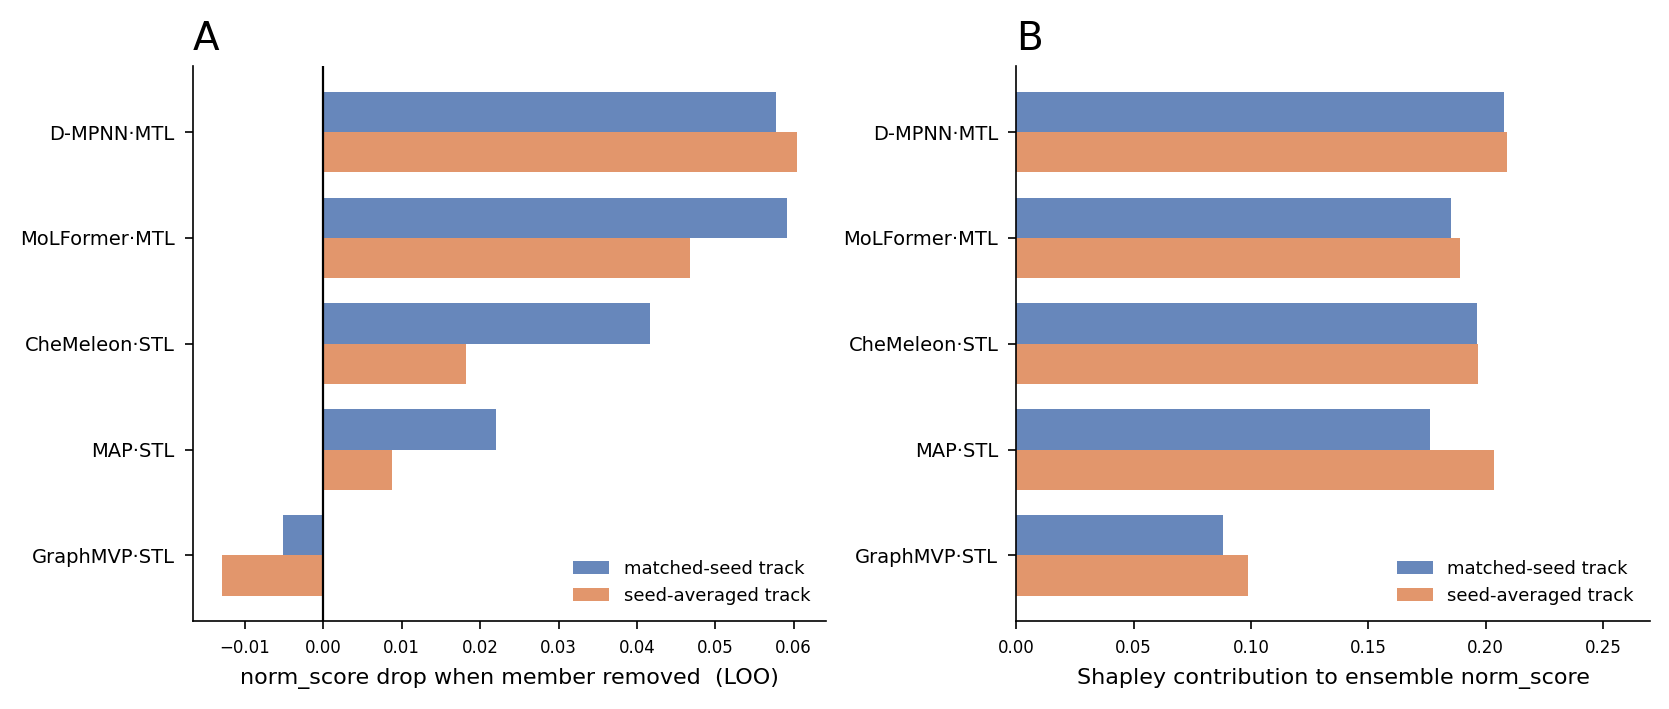

In [4]:
# === figureS5.png (Supplementary: ensemble-member roles — leave-one-out & Shapley) ===
import numpy as np, matplotlib.pyplot as plt
apply_figure_style(sizes=(8,7,6))
GT = _GT
PRETTY = {
 "stl_chemeleon":"CheMeleon·STL","mtl_chemeleon":"CheMeleon·MTL",
 "stl_map":"MAP·STL","mtl_map":"MAP·MTL",
 "stl_dmpnn":"D-MPNN·STL","mtl_dmpnn":"D-MPNN·MTL",
 "stl_graphmvp":"GraphMVP·STL","mtl_graphmvp":"GraphMVP·MTL",
 "stl_molformer":"MoLFormer·STL","mtl_molformer":"MoLFormer·MTL",
}
ls=GT["loo_shapley"]
members=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_map","stl_graphmvp"]  # k=5, plot order
mpretty=[PRETTY[m] for m in members]
y=np.arange(len(members))[::-1]; bw=0.38

plt.close('all')
fig=plt.figure(figsize=(9.4,3.6))
gs=fig.add_gridspec(1,2, wspace=0.30)

# Panel a: leave-one-out norm_score drop per member (ls[m] = [within_solo,loo_within,cross_solo,loo_cross,shap_within,shap_cross])
axA=fig.add_subplot(gs[0,0])
loo_w=[ls[m][1] for m in members]; loo_c=[ls[m][3] for m in members]
axA.barh(y+bw/2, loo_w, height=bw, color="#4c72b0", label="matched-seed track", alpha=0.85)
axA.barh(y-bw/2, loo_c, height=bw, color="#dd8452", label="seed-averaged track", alpha=0.85)
axA.axvline(0, color="black", lw=0.8)
axA.set_yticks(y); axA.set_yticklabels(mpretty, fontsize=7)
axA.set_xlabel("norm_score drop when member removed  (LOO)")
axA.set_title("A", fontsize=14)
# axA.set_title("a  Leave-one-out: complementary roles", loc="left", fontweight="bold", fontsize=9)
axA.legend(fontsize=6.5, frameon=False, loc="lower right")
gy=np.arange(len(members))[::-1][members.index("stl_graphmvp")]
# axA.text(0.004, gy, "removal improves\nconsensus (\u0394<0)", fontsize=6, color="#3a7d44", ha="left", va="center")

# Panel b: Shapley contributions per member (both tracks)
axB=fig.add_subplot(gs[0,1])
sh_w=[ls[m][4] for m in members]; sh_c=[ls[m][5] for m in members]
axB.barh(y+bw/2, sh_w, height=bw, color="#4c72b0", label="matched-seed track", alpha=0.85)
axB.barh(y-bw/2, sh_c, height=bw, color="#dd8452", label="seed-averaged track", alpha=0.85)
axB.set_yticks(y); axB.set_yticklabels(mpretty, fontsize=7)
axB.set_xlabel("Shapley contribution to ensemble norm_score")
axB.set_title("B", fontsize=14)
# axB.set_title("b  Shapley: all members contribute", loc="left", fontweight="bold", fontsize=9)
axB.legend(fontsize=6.5, frameon=False, loc="lower right")
# for yi,(w_,c_) in zip(y,zip(sh_w,sh_c)):
#     axB.text(max(w_,c_)+0.004, yi, f"{w_:.3f}/{c_:.3f}", va="center", fontsize=5.5, color="#444")
axB.set_xlim(0, 0.27)

fig.savefig(os.path.join(OUTDIR,"figureS5.png"), dpi=300, bbox_inches="tight")
print("saved figureS5.png (LOO + Shapley)")


## Table S4 — Inter-model correlation among the five k=5 members

Inter-member dependence among the five k = 5 ensemble members: the mean absolute off-diagonal correlation of their standardized predictions and of their residuals (errors), on each track. High values indicate the members are strongly correlated, so the ensemble gain is not driven by error decorrelation.

In [5]:
# --- Table S4: inter-model correlation among the five k=5 ensemble members ---
corr=_GT["corr"]  # {'within':{'pred_offdiag','resid_offdiag'}, 'cross':{...}}
rows=[["matched-seed track", f'{corr["within"]["pred_offdiag"]:.3f}', f'{corr["within"]["resid_offdiag"]:.3f}'],
      ["seed-averaged track", f'{corr["cross"]["pred_offdiag"]:.3f}', f'{corr["cross"]["resid_offdiag"]:.3f}']]
S4=pd.DataFrame(rows, columns=["Track","Prediction corr (mean |off-diag|)","Residual/error corr (mean |off-diag|)"])
register("tableS4_inter_model_corr", S4)
assert S4.iloc[0]["Prediction corr (mean |off-diag|)"]=="0.767" and S4.iloc[0]["Residual/error corr (mean |off-diag|)"]=="0.837", S4.iloc[0].to_dict()
print("S4 OK", S4.shape); S4


S4 OK (2, 3)


,Track,Prediction corr (mean |off-diag|),Residual/error corr (mean |off-diag|)
0,matched-seed track,0.767,0.837
1,seed-averaged track,0.878,0.899


## Fig. S4 Inter-member correlation heatmaps (predictions and errors)

figureS4.png written | within pred/resid off-diag 0.767 0.837 | cross 0.878 0.899


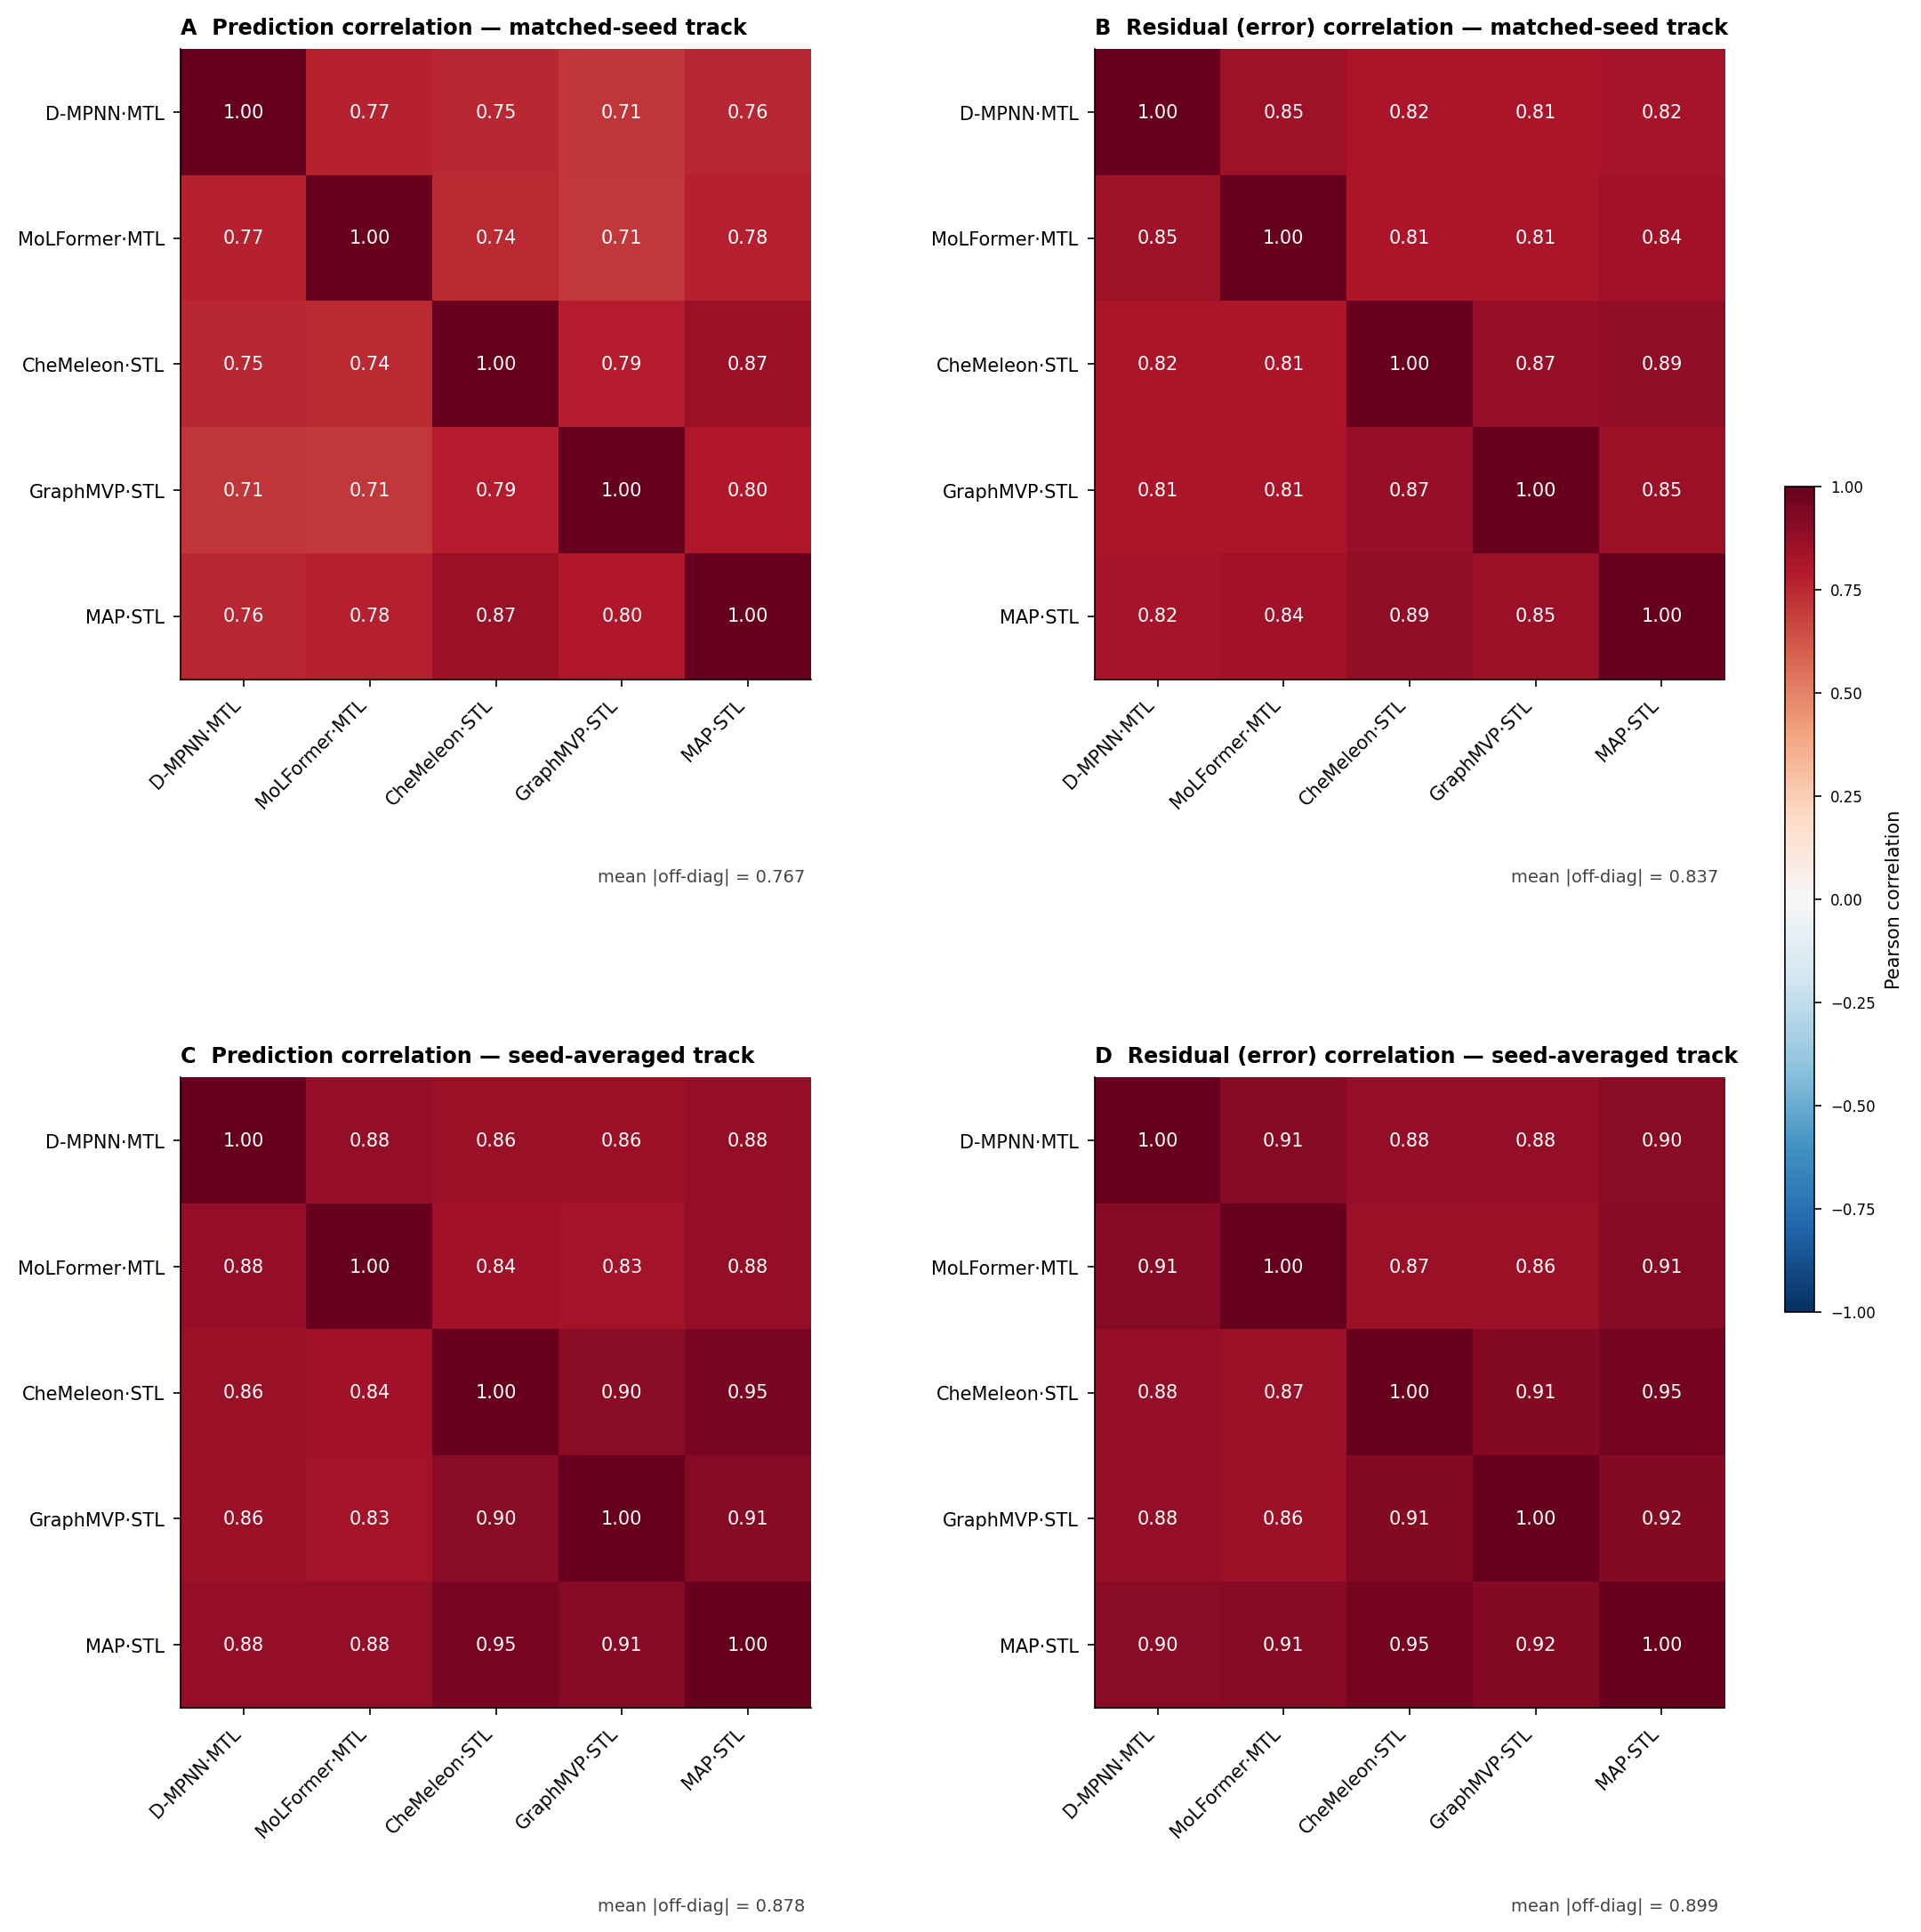

In [6]:
# === figureS4.png (Supplementary: inter-member correlation heatmaps, diagonal included) ===
# Full 5x5 correlation matrices among the k=5 ensemble members, for both standardized
# PREDICTIONS and standardized RESIDUALS (errors), on both tracks. Same recipe as Table S4
# (corr_matrices in setup) but returning the full matrix instead of the off-diagonal mean.
# The mean |off-diagonal| of each matrix equals the corresponding Table S4 entry (asserted).
import numpy as np, matplotlib.pyplot as plt

def _corr_full(within):
    """Full (pred_corr_mat, resid_corr_mat) 5x5 for the k=5 members — same standardization
    and averaging as setup's corr_matrices(), but returning the matrices (diagonal = 1)."""
    pred_cols=[f"p_{m}" for m in ENSEMBLE]; base=merge_uniform(ENSEMBLE, within)
    if not within:
        pz={m:[] for m in ENSEMBLE}; rz={m:[] for m in ENSEMBLE}
        for task in TASKS:
            rows=base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y=rows.y_true.to_numpy(float); P=rows[pred_cols].to_numpy(float)
            for j,m in enumerate(ENSEMBLE):
                p=P[:,j]; pz[m].append((p-p.mean())/(p.std()+1e-9))
                r=p-y; rz[m].append((r-r.mean())/(r.std()+1e-9))
        pz={m:np.concatenate(v) for m,v in pz.items()}; rz={m:np.concatenate(v) for m,v in rz.items()}
        Pm=np.corrcoef([pz[m] for m in ENSEMBLE]); Rm=np.corrcoef([rz[m] for m in ENSEMBLE])
    else:
        seeds=sorted(base.seed.unique()); pmats=[]; rmats=[]
        for task in TASKS:
            tr=base[base.task==task]
            for seed in seeds:
                sr=tr[(tr.seed==seed)&(tr.split=="test")].dropna(subset=["y_true"])
                if len(sr)<3: continue
                y=sr.y_true.to_numpy(float); P=sr[pred_cols].to_numpy(float)
                pzs=[]; rzs=[]
                for j,m in enumerate(ENSEMBLE):
                    p=P[:,j]; pzs.append((p-p.mean())/(p.std()+1e-9))
                    rzs.append((p-y)-(p-y).mean()/((p-y).std()+1e-9))
                pmats.append(np.corrcoef(pzs)); rmats.append(np.corrcoef(rzs))
        Pm=np.nanmean(pmats,0); Rm=np.nanmean(rmats,0)
    return Pm, Rm

PRETTY={"stl_chemeleon":"CheMeleon\u00b7STL","mtl_dmpnn":"D-MPNN\u00b7MTL","mtl_molformer":"MoLFormer\u00b7MTL",
        "stl_graphmvp":"GraphMVP\u00b7STL","stl_map":"MAP\u00b7STL"}
_labels=[PRETTY[m] for m in ENSEMBLE]
Pw,Rw=_corr_full(True)    # matched-seed track
Pc,Rc=_corr_full(False)   # seed-averaged track

# verify against Table S4 off-diagonal means
_off=np.triu_indices(len(ENSEMBLE),1)
for mat,exp in [(Pw,0.767),(Rw,0.837),(Pc,0.878),(Rc,0.899)]:
    assert abs(float(np.abs(mat[_off]).mean())-exp)<0.005, (float(np.abs(mat[_off]).mean()),exp)

apply_figure_style(sizes=(8,7,6))
plt.close('all')
fig,axes=plt.subplots(2,2,figsize=(11.2,11.6))
fig.subplots_adjust(hspace=0.55, wspace=0.45, top=0.92, bottom=0.10, right=0.90)
panels=[(axes[0,0],Pw,"A  Prediction correlation \u2014 matched-seed track"),
        (axes[0,1],Rw,"B  Residual (error) correlation \u2014 matched-seed track"),
        (axes[1,0],Pc,"C  Prediction correlation \u2014 seed-averaged track"),
        (axes[1,1],Rc,"D  Residual (error) correlation \u2014 seed-averaged track")]
n=len(ENSEMBLE)
for ax,M,title in panels:
    im=ax.imshow(M,cmap="RdBu_r",vmin=-1,vmax=1,aspect="equal")
    ax.set_xticks(range(n)); ax.set_xticklabels(_labels,rotation=45,ha="right",fontsize=7.5)
    ax.set_yticks(range(n)); ax.set_yticklabels(_labels,fontsize=7.5)
    for i in range(n):
        for j in range(n):
            v=M[i,j]
            ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7.5,
                    color="white" if abs(v)>0.6 else "black")
    ax.set_title(title,loc="left",fontweight="bold",fontsize=8.6)
    off=float(np.abs(M[_off]).mean())
    ax.text(0.99,-0.30,f"mean |off-diag| = {off:.3f}",transform=ax.transAxes,ha="right",va="top",fontsize=7,color="#444")
cax=fig.add_axes([0.93,0.30,0.015,0.4]); cb=fig.colorbar(im,cax=cax); cb.set_label("Pearson correlation",fontsize=7.5)
# fig.suptitle("Inter-member correlation among the five k=5 ensemble members (diagonal = self-correlation = 1)",
#              fontweight="bold",fontsize=9.5,y=0.985)
fig.savefig(os.path.join(OUTDIR,"figureS4.png"),dpi=300,bbox_inches="tight")
print("figureS4.png written | within pred/resid off-diag",
      round(float(np.abs(Pw[_off]).mean()),3), round(float(np.abs(Rw[_off]).mean()),3),
      "| cross", round(float(np.abs(Pc[_off]).mean()),3), round(float(np.abs(Rc[_off]).mean()),3))
plt.show()


*Figure S4. Full 5×5 correlation matrices among the five k = 5 ensemble members, for the standardized predictions (left) and the standardized residuals/errors (right), on the matched-seed (top) and seed-averaged (bottom) tracks. The diagonal is the self-correlation (= 1); the mean absolute off-diagonal value of each matrix, printed below each panel, is the corresponding entry of Supplementary Table S4. The uniformly high off-diagonal values show that the members are strongly correlated in both their predictions and their errors, so the ensemble gain is not driven by error decorrelation.*